# 02c - NEWAVE: cenário "mediana" (cor mediana + distribuição completa)

Parte do **cenário mesma série** (`02b`): GSF e preço das **mesmas 25 séries** escolhidas pela trajetória de ENA.
**Única mudança:** a regra da cor exibida.

| | Cenário mesma série | Cenário mediana |
|---|---|---|
| Cor exibida (séries) | ábaco com GSF médio e PLD médio ("cor pelas médias") | **cor mediana** da distribuição das 25 séries |
| Cor exibida (Dcide) | ábaco com GSF médio e preço da Dcide | **cor mediana** da distribuição: GSF de cada uma das 25 séries com o preço da Dcide |
| Texto | distribuição das séries | **distribuição completa** nas duas linhas |

**Cor mediana:** ordenando as cores (verde < amarela < vermelha 1 < vermelha 2), é a primeira em que a probabilidade
acumulada chega a 50% — "com pelo menos 50% de chance, a bandeira será esta cor ou mais barata".
A ENA de referência é a real (oráculo). Figuras em `reports/figures/cenario_mediana/`.

In [1]:
import pandas as pd
from IPython.display import Image, display

from forecast_bandeiras import graficos, load, newave, regra

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
base = pd.read_parquet(load.DATA_PROCESSED / "base_mensal.parquet").loc["2026"]
base.index = base.index.month
base["cor_oficial"] = [c if isinstance(c, str) else r for c, r in zip(base.cor_boletim, base.cor_regra)]
ALVOS = [5, 6, 8, 10]
ABREV = {"Verde": "Vd", "Amarela": "Am", "Vermelha 1": "V1", "Vermelha 2": "V2"}
PASTA = "cenario_mediana"


def texto_prob(prob):
    itens = [f"{ABREV[c]} {v:.0%}" for c, v in prob.items() if v >= 0.05]
    return " ".join(itens[:2]) + ("\n" + " ".join(itens[2:]) if len(itens) > 2 else "")

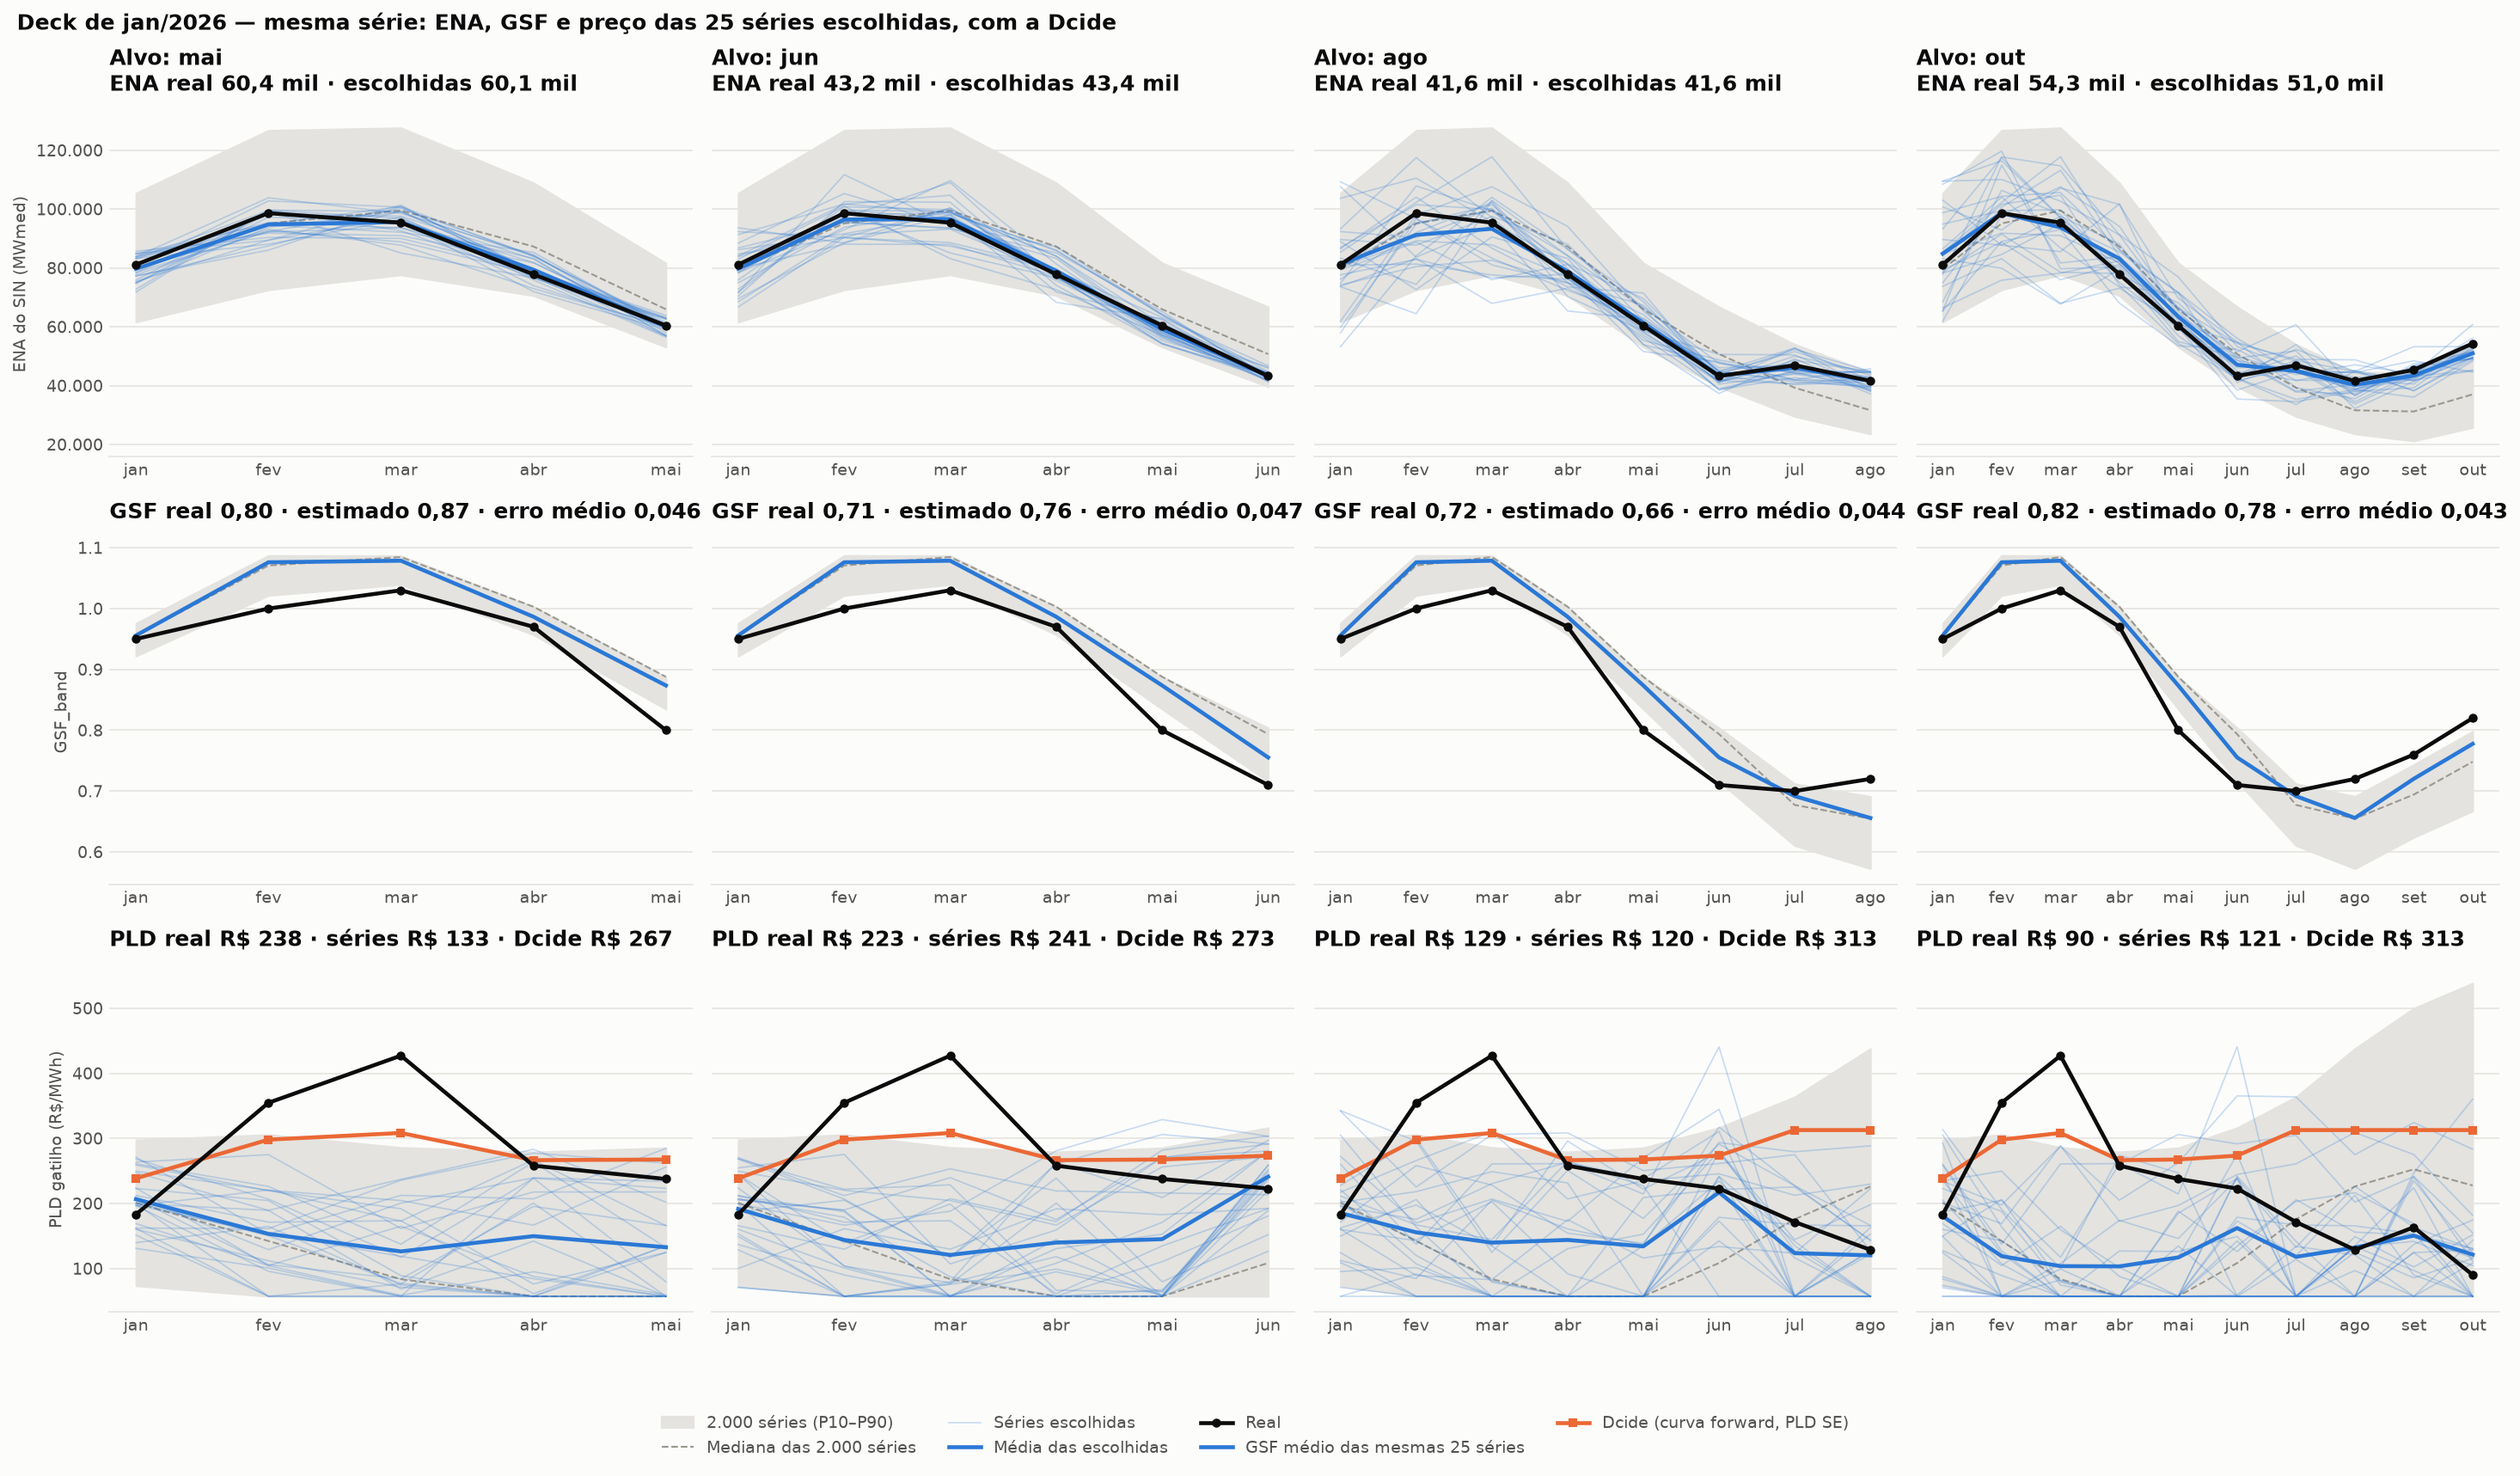

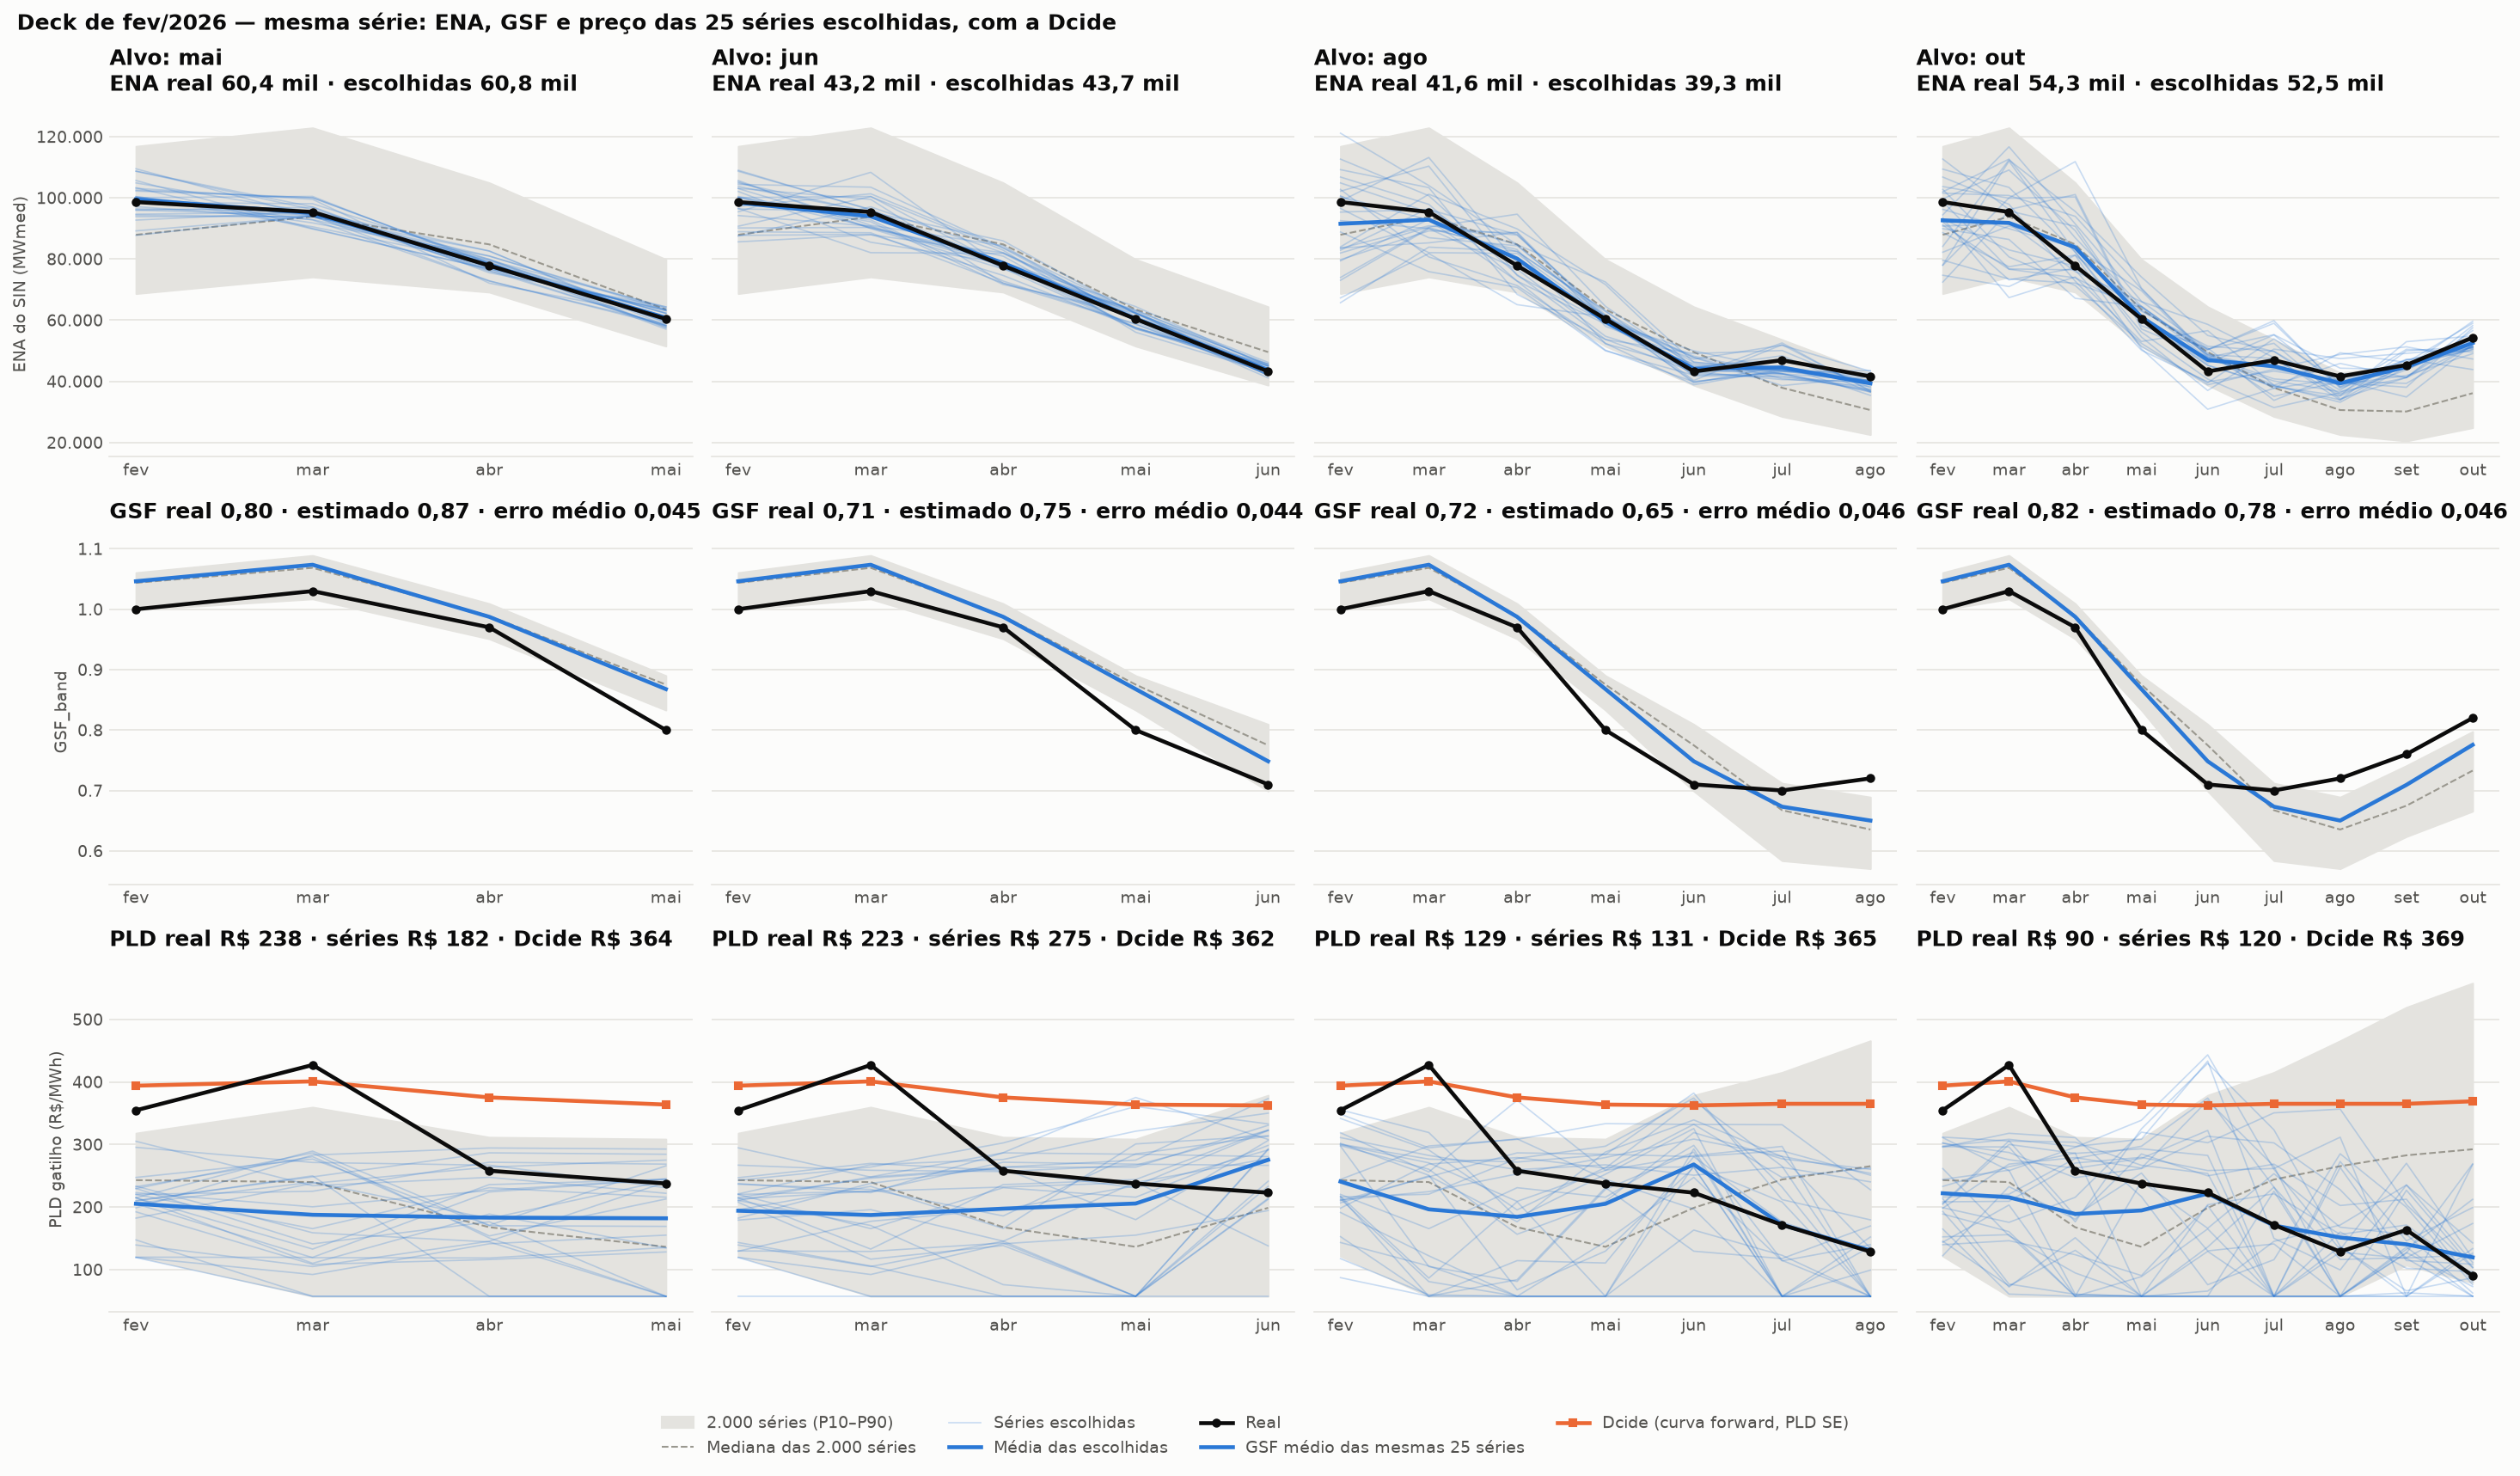

In [2]:
tabelas, comparacao = {}, []
for mes_deck in (1, 2):
    deck = newave.carregar_deck(2026, mes_deck)
    meses = list(range(mes_deck, 11))
    ena = deck["ena_sin"][meses]
    gsf = newave.gsf_series(deck, base.loc[meses])
    pld = newave.pld_gatilho_series(deck, meses, base.pld_min_boletim.iloc[0], base.pld_max_boletim.max())
    dcide = load.ler_dcide(2026, mes_deck)
    dcide = dcide[dcide.index.year == 2026]
    dcide.index = dcide.index.month
    esc = {m: newave.escolher_series(ena, base.loc[mes_deck:m, "ena_sin"], k=25) for m in meses}
    nome = f"{graficos.MESES[mes_deck - 1]}/2026"
    display(Image(graficos.trajetorias_deck(
        ena, gsf, pld, base, {a: esc[a] for a in ALVOS}, esc, dcide,
        f"Deck de {nome} — mesma série: ENA, GSF e preço das 25 séries escolhidas, com a Dcide",
        f"{PASTA}/08_trajetorias_deck_{mes_deck:02d}.png",
        rotulo_gsf="GSF médio das mesmas 25 séries")))
    linhas = {}
    for m in meses:
        real = base.loc[m, "cor_oficial"]
        g, p = gsf.loc[esc[m], m], pld.loc[esc[m], m]
        prob = newave.probabilidade_cores_pareada(g, p)
        prob_dc = newave.probabilidade_cores_pareada(g, pd.Series(dcide.loc[m], index=g.index))
        cor_med, cor_med_dc = newave.cor_mediana(prob), newave.cor_mediana(prob_dc)
        linhas[m] = {"cor_real": real, "cor_series": cor_med, "prob_series": texto_prob(prob),
                     "cor_dcide": cor_med_dc, "prob_dcide": texto_prob(prob_dc)}
        comparacao.append({
            "deck": nome, "mes": m, "real": real,
            "séries — pelas médias (02b)": regra.cor_bandeira(round(g.mean(), 2), p.mean()),
            "séries — mediana (02c)": cor_med,
            "Dcide — pelas médias (02b)": regra.cor_bandeira(round(g.mean(), 2), dcide.loc[m]),
            "Dcide — mediana (02c)": cor_med_dc,
            "prob. da cor real (séries)": prob[real], "prob. da cor real (Dcide)": prob_dc[real],
        })
    tabelas[f"Deck de {nome}"] = pd.DataFrame(linhas).T

## Bandeira: real × séries do NEWAVE × Dcide (cor mediana e distribuição completa)

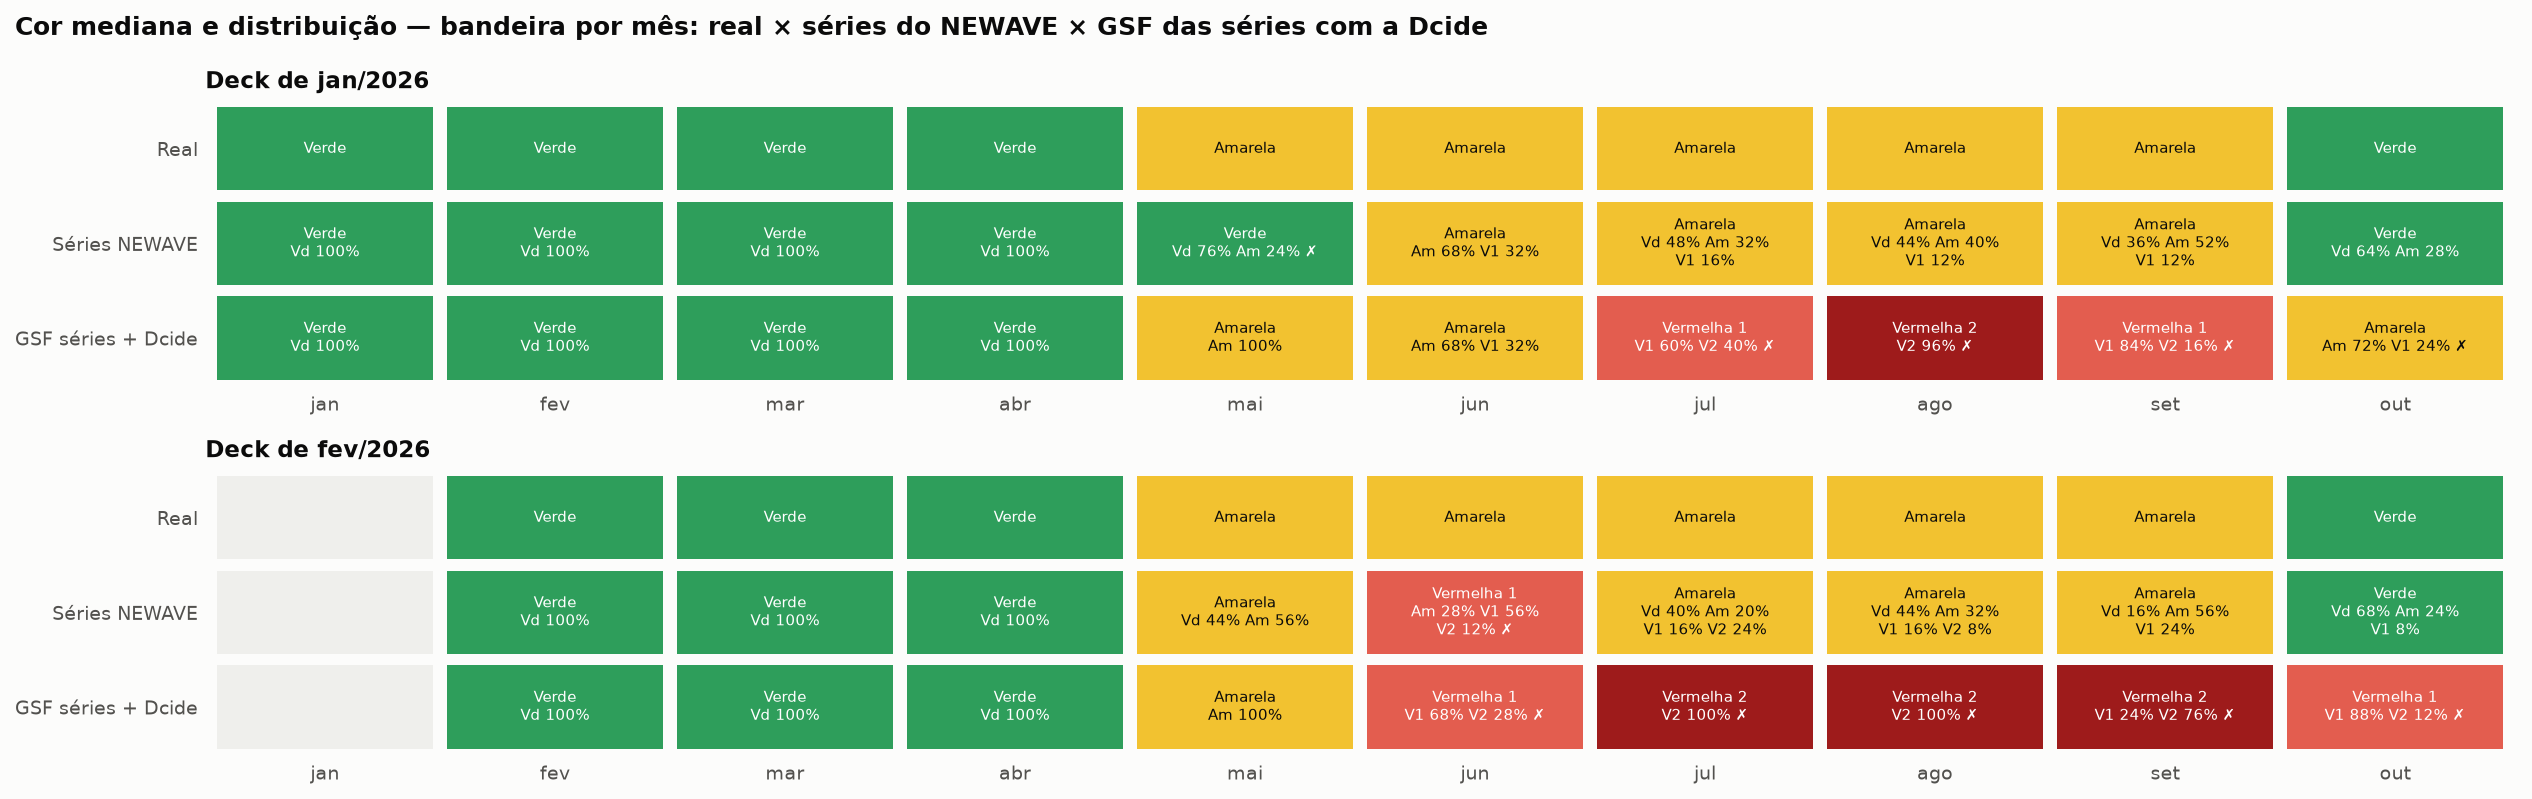

In [3]:
display(Image(graficos.faixa_bandeiras(
    tabelas, "Cor mediana e distribuição — bandeira por mês: real × séries do NEWAVE × GSF das séries com a Dcide",
    f"{PASTA}/09_bandeiras_series_dcide.png")))

## Comparação com o cenário mesma série (regra da cor)

In [4]:
comp = pd.DataFrame(comparacao)
regras = ["séries — pelas médias (02b)", "séries — mediana (02c)", "Dcide — pelas médias (02b)", "Dcide — mediana (02c)"]
resumo = pd.DataFrame({r: comp.groupby("deck", sort=False).apply(lambda d, r=r: (d[r] == d.real).sum()) for r in regras})
resumo["meses"] = comp.groupby("deck", sort=False).size()
resumo["prob. média da cor real (séries)"] = comp.groupby("deck", sort=False)["prob. da cor real (séries)"].mean()
resumo["prob. média da cor real (Dcide)"] = comp.groupby("deck", sort=False)["prob. da cor real (Dcide)"].mean()
resumo

,séries — pelas médias (02b),séries — mediana (02c),Dcide — pelas médias (02b),Dcide — mediana (02c),meses,prob. média da cor real (séries),prob. média da cor real (Dcide)
deck,,,,,,,
jan/2026,9,9,6,6,10,0.680,0.568
fev/2026,8,8,4,4,9,0.622,0.449


In [5]:
comp[comp["séries — pelas médias (02b)"] != comp["séries — mediana (02c)"]]

,deck,mes,real,séries — pelas médias (02b),séries — mediana (02c),Dcide — pelas médias (02b),Dcide — mediana (02c),prob. da cor real (séries),prob. da cor real (Dcide)
13,fev/2026,5,Amarela,Verde,Amarela,Amarela,Amarela,0.560,1.000
14,fev/2026,6,Amarela,Amarela,Vermelha 1,Vermelha 1,Vermelha 1,0.280,0.040
